In [4]:
from qiskit.quantum_info import Operator
from qiskit.quantum_info import Statevector
from numpy import sqrt
from qiskit.visualization import array_to_latex
from qiskit.visualization import plot_histogram

Y = Operator([[0, -1.0j], [1.0j, 0]])
H = Operator([[1 / sqrt(2), 1 / sqrt(2)], [1 / sqrt(2), -1 / sqrt(2)]])
S = Operator([[1, 0], [0, 1.0j]])
T = Operator([[1, 0], [0, (1 + 1.0j) / sqrt(2)]])

v = Statevector([1, 0])

v = v.evolve(H) #hadamard, the 50/50 thing
v = v.evolve(T) #T is a 45 angle tilt
v = v.evolve(H) #hadamard once again
v = v.evolve(S) #S is a 90 tilt, so 45+90 is 135 tilt
v = v.evolve(Y) #the flip sing thingy, poor qubit, tossed around in those gates:_(

display(v.draw("latex"))

<IPython.core.display.Latex object>

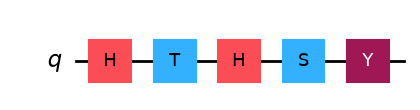

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

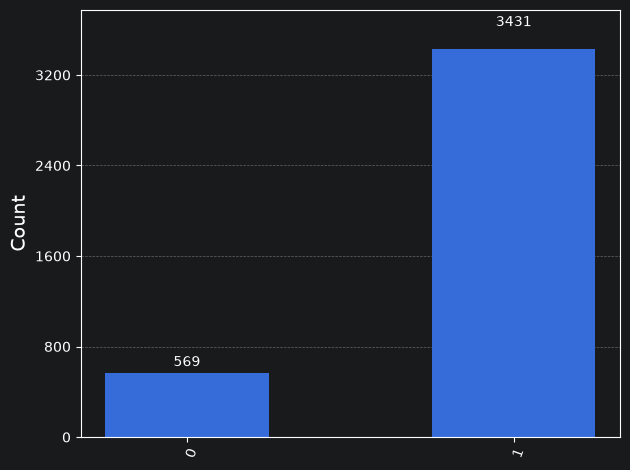

In [8]:
from qiskit import QuantumCircuit

circuit = QuantumCircuit(1)

circuit.h(0)
circuit.t(0)
circuit.h(0)
circuit.s(0)
circuit.y(0)

display(circuit.draw(output="mpl"))
display(Operator.from_circuit(circuit).draw("latex")) #THIS IS INCREDIBLE INVENTION
#THE .from_circuit MULTIPLIES ALL THE COMPLEX MATRICES TOGETHER AND GIVES OUT THE SHORT-CUT MATRIX
#the output form the top code corresponds to the first column in the matrix (ket 0), because we started with 0.

ket0 = Statevector([1, 0])
v = ket0.evolve(circuit)
display(v.draw("latex"))


statistics = v.sample_counts(4000)
display(plot_histogram(statistics))